**Human Movement Intelligence | Presented by: Reza Saadatyar (2026)**

**19 | Subject-Disjoint Temperature Calibration**

![alt text](19_workflow.svg)

**Objective:** Evaluate scalar temperature scaling for a weighted CNN using separate Train, Calibration and Validation participants within each Development fold.

**Dataset:** The 29-participant HARTH v2.0 Development cohort, excluding reserved Test identities S023 and S032.

**Notebook Scope:** Fit CNN preprocessing and weights on Train only, estimate temperature using Calibration labels and evaluate probability metrics on disjoint outer Validation participants. These results describe Development calibration, not independent final Test or clinical uncertainty validation.

**01. Imports and Reusable Calibration Functions**

In [1]:
# ============== 01. Imports and Calibration Research Utilities ===============

# ------------------- 1. Import standard-library path tools -------------------
import sys
from pathlib import Path

# --------------------- 2. Import numeric research arrays ---------------------
import numpy as np

# -------------------- 3. Import source and result tables ---------------------
import pandas as pd

# ------------ 4. Plot probability metrics and reliability figures ------------
import matplotlib.pyplot as plt

# ---------------- 5. Import PyTorch for temporal CNN fitting -----------------
import torch

# ------------------- 6. Display notebook research results --------------------
from IPython.display import display

# ----------------- 7. Set up participant-disjoint GroupKFold -----------------
from sklearn.model_selection import GroupKFold

# -------------------- 8. Resolve repository root portably --------------------
root=Path.cwd().resolve()

# -------------- 9. Locate original reusable source directories ---------------
while not (root/"code/python/src/core/data_loading.py").is_file():
    if root.parent==root: raise RuntimeError("Open within the project repository.")
    root=root.parent

# -------------------- 10. Register shared Python modules ---------------------
sys.path.insert(0,str(root/"code/python/src"))

# -------------------- 11. Register HARTH research modules --------------------
sys.path.insert(0,str(root/"studies/wearable_activity_recognition/src"))

# ----------------- 12. Import nested HARTH data preparation ------------------
from harth_data import HARTH_SUBJECTS,prepare_harth_nested_window_cohort

# -------------- 13. Import CNN fitting and softmax predictions ---------------
from core.temporal_cnn import train_temporal_cnn_fixed_steps,predict_temporal_cnn_probabilities

# ------------- 14. Import temperature scaling and scoring rules --------------
from core.temperature_calibration import fit_temperature,apply_temperature,multiclass_nll

# ---------------- 15. Import reliability and confidence audit ----------------
from core.prediction_reliability import audit_prediction_confidence

# ----------------- 16. Display the saved PyTorch environment -----------------
print("PyTorch:",torch.__version__)

PyTorch: 2.12.1+cpu


**02. Construct Development Data and Outer Participant Folds**

Build three outer subject-disjoint Development folds from the previously defined nested cohort. Reserve outer Validation participants before creating inner Train and Calibration groups. S023 and S032 are not loaded.

In [2]:
# ============== 02. Prepare Nested Development and Outer Folds ===============

# -------------- 1. Protect original reserved Test participants ---------------
RESERVED_TEST={"S023","S032"}

# -------------------- 2. Select all 29 Development people --------------------
SUBJECTS=sorted(set(HARTH_SUBJECTS)-RESERVED_TEST)

# --------------- 3. Fix the eight documented activity classes ----------------
CLASSES=tuple(range(1,9))

# ------------------ 4. Construct nested source window data -------------------
X,metadata,overview=prepare_harth_nested_window_cohort(
    SUBJECTS,root/"data/raw/harth_v2",task_classes=CLASSES,
    base_cap=500,expanded_cap=1000,
    window_size=100,step_size=50,sampling_rate=50
)

# ---------------- 5. Recover original base-500 window indices ----------------
base=np.flatnonzero(metadata["in_base_500"].to_numpy(dtype=bool))

# -------------------- 6. Retain original activity labels ---------------------
y=metadata["label"].to_numpy()

# ----------------- 7. Align original participant identities ------------------
groups=metadata["subject_id"].to_numpy()

# --------------- 8. Check Development and source-window counts ---------------
assert len(SUBJECTS)==29 and len(base)==14201

# ------------------ 9. Exclude both protected Test subjects ------------------
assert not(set(groups)&RESERVED_TEST)

# --------------- 10. Create three outer subject-disjoint folds ---------------
folds=list(GroupKFold(n_splits=3).split(
    np.zeros(len(base)),y[base],groups=groups[base]))

# --------------- 11. Report original and expanded source sizes ---------------
print("Prepared",len(base),"base Validation candidates and",len(X),"expanded windows")

Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S006.csv
HARTH subject S006: 408,709 rows, 6 sensors
Input signal: 408,709 samples, 6 channels
Candidate windows: 8,173
Retained windows: 7,441 | Shape: (7441, 6, 100)
Rejected candidates: 732
Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S008.csv
HARTH subject S008: 418,989 rows, 6 sensors
Input signal: 418,989 samples, 6 channels
Candidate windows: 8,378
Retained windows: 7,564 | Shape: (7564, 6, 100)
Rejected candidates: 814
Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S009.csv
HARTH subject S009: 154,464 rows, 6 sensors
Input signal: 154,464 samples, 6 channels
Candidate windows: 3,088
Retained windows: 2,885 | Shape: (2885, 6, 100)
Rejected candidates: 203
Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S010.csv
HARTH subject S010: 351,649 rows, 6 sensors
Input signal: 351,649 samples, 6 channels
Candidate windows: 7,031
Retai

D:\human-movement-intelligence\studies\wearable_activity_recognition\src\harth_data.py:424: UserWarning: Unexpected HARTH activity codes: [10, 11, 17] (4,512 rows in S030.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(path, allow_unmapped_labels=True)


HARTH subject S030: 245,994 rows, 6 sensors
Input signal: 245,994 samples, 6 channels
Candidate windows: 4,918
Retained windows: 3,335 | Shape: (3335, 6, 100)
Rejected candidates: 1,583
Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S031.csv


D:\human-movement-intelligence\studies\wearable_activity_recognition\src\harth_data.py:424: UserWarning: Unexpected HARTH activity codes: [10, 11] (334 rows in S031.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(path, allow_unmapped_labels=True)


HARTH subject S031: 269,560 rows, 6 sensors
Input signal: 269,560 samples, 6 channels
Candidate windows: 5,390
Retained windows: 4,411 | Shape: (4411, 6, 100)
Rejected candidates: 979
Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S033.csv
HARTH subject S033: 201,688 rows, 6 sensors
Input signal: 201,688 samples, 6 channels
Candidate windows: 4,032
Retained windows: 3,687 | Shape: (3687, 6, 100)
Rejected candidates: 345
Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S034.csv
HARTH subject S034: 188,202 rows, 6 sensors
Input signal: 188,202 samples, 6 channels
Candidate windows: 3,763
Retained windows: 3,351 | Shape: (3351, 6, 100)
Rejected candidates: 412
Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S035.csv
HARTH subject S035: 181,251 rows, 6 sensors
Input signal: 181,251 samples, 6 channels
Candidate windows: 3,624
Retained windows: 3,337 | Shape: (3337, 6, 100)
Rejected candidates: 287
Using cached HA

D:\human-movement-intelligence\studies\wearable_activity_recognition\src\harth_data.py:424: UserWarning: Unexpected HARTH activity codes: [10] (1,422 rows in S037.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(path, allow_unmapped_labels=True)


HARTH subject S037: 206,379 rows, 6 sensors
Input signal: 206,379 samples, 6 channels
Candidate windows: 4,126
Retained windows: 3,468 | Shape: (3468, 6, 100)
Rejected candidates: 658
Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S038.csv
HARTH subject S038: 184,992 rows, 6 sensors
Input signal: 184,992 samples, 6 channels
Candidate windows: 3,698
Retained windows: 3,355 | Shape: (3355, 6, 100)
Rejected candidates: 343
Prepared 14201 base Validation candidates and 28201 expanded windows


**03. Separate Train, Calibration and Validation Participants**

Within each outer fold, allocate approximately 80% of the remaining participants to Train and 20% to Calibration. CNN scaling and class weights are fitted on Train; temperature uses Calibration labels only. Outer Validation participants have no overlap with either group.

In [3]:
# ============== 03. Separate Train, Calibration and Validation ===============

# ---------------- 1. Import inner participant-level splitting ----------------
from sklearn.model_selection import GroupShuffleSplit

# ----------------- 2. Select the recorded CPU or GPU device ------------------
device="cuda" if torch.cuda.is_available() else "cpu"

# ---------------- 3. Prepare out-of-fold probability records -----------------
oof_records=[]

# ---------------------- 4. Prepare fold metric records -----------------------
fold_records=[]

# ----------- 5. Run subject-disjoint Train/Calibration/Validation ------------
for fold,(outer_train,outer_valid) in enumerate(folds,start=1):
    outer_train_rows=base[outer_train]
    validation_rows=base[outer_valid]
    inner=GroupShuffleSplit(n_splits=1,test_size=0.2,random_state=42+fold)
    inner_train,inner_cal=next(inner.split(
        np.zeros(len(outer_train_rows)),y[outer_train_rows],groups[outer_train_rows]))
    train_people=set(groups[outer_train_rows[inner_train]])
    cal_people=set(groups[outer_train_rows[inner_cal]])
    valid_people=set(groups[validation_rows])
    assert not(train_people&cal_people or train_people&valid_people or cal_people&valid_people)
    train_rows=np.flatnonzero(np.isin(groups,list(train_people)))
    cal_rows=outer_train_rows[inner_cal]  # Original 500-cap Calibration rows only
    assert set(CLASSES).issubset(set(y[train_rows]))
    print(f"Fold {fold}: Train={len(train_people)}, Calibration={len(cal_people)}, Validation={len(valid_people)} subjects")
    model,history,_,stats=train_temporal_cnn_fixed_steps(
        X[train_rows],y[train_rows],X[cal_rows],y[cal_rows],
        classes=CLASSES,max_steps=400,eval_every=400,batch_size=128,
        learning_rate=1e-3,seed=42,device=device,class_weighting="inverse_sqrt")
    cal_prob=predict_temporal_cnn_probabilities(model,X[cal_rows],stats,CLASSES,device=device)
    temp_fit=fit_temperature(cal_prob,y[cal_rows],CLASSES)
    raw=predict_temporal_cnn_probabilities(model,X[validation_rows],stats,CLASSES,device=device)
    scaled=apply_temperature(raw,temp_fit["temperature"])
    for name,p in [("Uncalibrated",raw),("Temperature scaled",scaled)]:
        _,bins,_,metrics=audit_prediction_confidence(
            y[validation_rows],p,groups[validation_rows],CLASSES)
        fold_records.append({
            "fold":fold,"method":name,"temperature":temp_fit["temperature"],
            "train_subjects":len(train_people),"calibration_subjects":len(cal_people),
            "validation_subjects":len(valid_people),"validation_windows":len(validation_rows),
            "nll":multiclass_nll(y[validation_rows],p,CLASSES),
            "ece":metrics["ece_10_bins"],"brier":metrics["multiclass_brier"],
            "accuracy":metrics["accuracy"]})
        oof_records.append(pd.DataFrame({
            "fold":fold,"method":name,"source_row":validation_rows,
            "subject_id":groups[validation_rows],"true_label":y[validation_rows],
            **{f"prob_{code}":p[:,i] for i,code in enumerate(CLASSES)}
        }))

# -------------------- 6. Assemble the paired fold metrics --------------------
fold_results=pd.DataFrame(fold_records)

# ------------- 7. Combine source-indexed held-out probabilities --------------
oof=pd.concat(oof_records,ignore_index=True)

# --------------- 8. Display original fold-specific score table ---------------
display(fold_results.round(4))

Fold 1: Train=15, Calibration=4, Validation=10 subjects
Step 400/400 | loss=0.4655 | Validation Macro F1=0.7474
Fold 2: Train=15, Calibration=4, Validation=10 subjects
Step 400/400 | loss=0.4938 | Validation Macro F1=0.8349
Fold 3: Train=16, Calibration=4, Validation=9 subjects
Step 400/400 | loss=0.4890 | Validation Macro F1=0.7737


,fold,method,temperature,train_subjects,calibration_subjects,validation_subjects,validation_windows,nll,ece,brier,accuracy
0,1,Uncalibrated,0.6322,15,4,10,5000,0.3313,0.0329,0.1471,0.8912
1,1,Temperature scaled,0.6322,15,4,10,5000,0.3834,0.0450,0.1515,0.8912
2,2,Uncalibrated,0.3943,15,4,10,4701,0.2201,0.0732,0.0942,0.9479
3,2,Temperature scaled,0.3943,15,4,10,4701,0.1999,0.0153,0.0790,0.9479
4,3,Uncalibrated,0.5096,16,4,9,4500,0.1990,0.0412,0.0851,0.9440
5,3,Temperature scaled,0.5096,16,4,9,4500,0.1905,0.0218,0.0826,0.9440


**04. Compare Probability Metrics by Fold**

Compare negative log-likelihood (NLL), expected calibration error (ECE), multiclass Brier score and accuracy before and after temperature scaling. The recorded fold means show lower ECE and Brier scores after calibration, but higher NLL, while classification accuracy remains unchanged. One fold worsened on all three probability metrics. ECE is also sensitive to the binning scheme.

nll                             ece               \
method Temperature scaled Uncalibrated Temperature scaled Uncalibrated   
fold                                                                     
1                  0.3834       0.3313             0.0450       0.0329   
2                  0.1999       0.2201             0.0153       0.0732   
3                  0.1905       0.1990             0.0218       0.0412   

                    brier                        accuracy               
method Temperature scaled Uncalibrated Temperature scaled Uncalibrated  
fold                                                                    
1                  0.1515       0.1471             0.8912       0.8912  
2                  0.0790       0.0942             0.9479       0.9479  
3                  0.0826       0.0851             0.9440       0.9440

,nll,ece,brier,accuracy
method,,,,
Temperature scaled,0.2580,0.0274,0.1044,0.9277
Uncalibrated,0.2501,0.0491,0.1088,0.9277


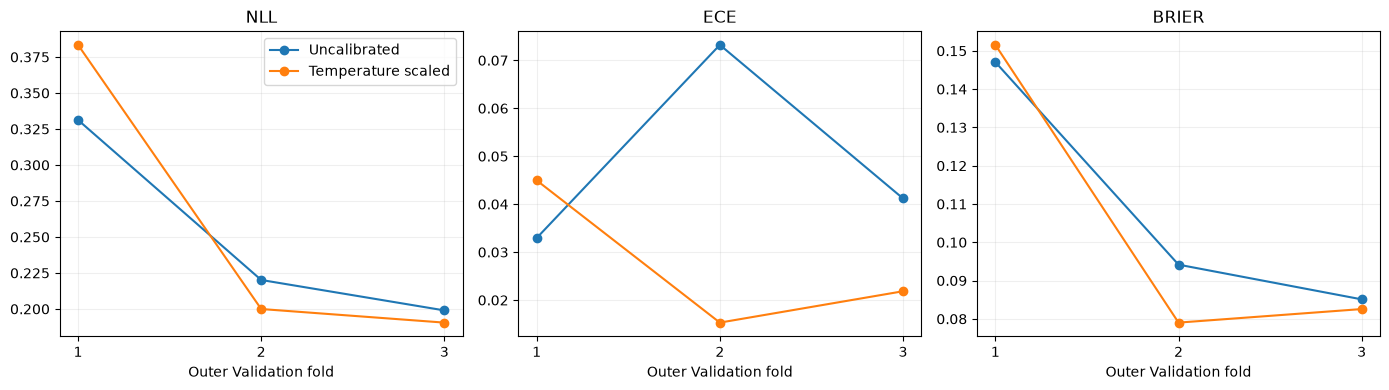

In [4]:
# ================ 04. Compare Fold-Level Calibration Metrics =================

# -------------- 1. Align four metrics for both methods per fold --------------
comparison=fold_results.pivot(index="fold",columns="method",values=["nll","ece","brier","accuracy"])

# ---------------- 2. Display the paired original fold metrics ----------------
display(comparison.round(4))

# -------------- 3. Compute descriptive means across three folds --------------
means=fold_results.groupby("method")[["nll","ece","brier","accuracy"]].mean()

# -------------- 4. Display means without concealing trade-offs ---------------
display(means.round(4))

# --------------- 5. Compare both methods across the same folds ---------------
fig,axes=plt.subplots(1,3,figsize=(14,4))

for ax,metric in zip(axes,["nll","ece","brier"]):
    for name,frame in fold_results.groupby("method",sort=False):
        ax.plot(frame["fold"],frame[metric],marker="o",label=name)
    ax.set(title=metric.upper(),xlabel="Outer Validation fold",xticks=[1,2,3])
    ax.grid(alpha=0.2)

axes[0].legend()
fig.tight_layout()
plt.show()

**05. Inspect Out-of-Fold Reliability**

Evaluate the two probability conditions on the same 14,201 base-window source rows, held out once per outer fold. Reliability plots are descriptive because windows overlap within participant recordings.

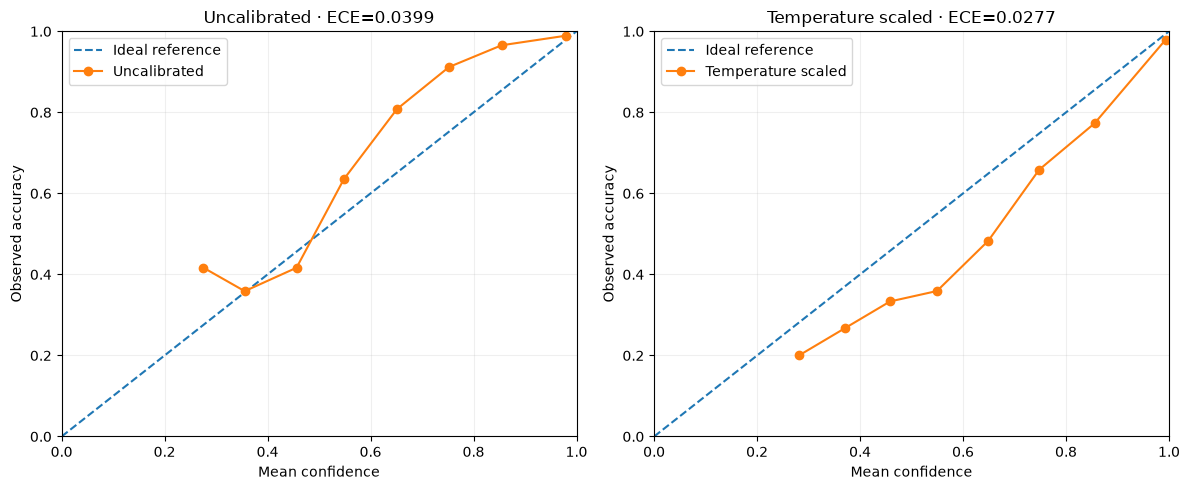

In [5]:
# ================ 05. Inspect Pooled Out-of-Fold Reliability =================

# -------------- 1. Inspect original source rows for each method --------------
fig,axes=plt.subplots(1,2,figsize=(12,5))

for ax,(name,table) in zip(axes,oof.groupby("method",sort=False)):
    table=table.sort_values("source_row")
    probabilities=table[[f"prob_{c}" for c in CLASSES]].to_numpy()
    _,bins,_,metrics=audit_prediction_confidence(
        table["true_label"].to_numpy(),probabilities,
        table["subject_id"].to_numpy(),CLASSES)
    selected=bins[bins["windows"]>0]
    ax.plot([0,1],[0,1],"--",label="Ideal reference")
    ax.plot(selected["mean_confidence"],selected["observed_accuracy"],
            marker="o",label=name)
    ax.set(xlim=(0,1),ylim=(0,1),title=f"{name} · ECE={metrics['ece_10_bins']:.4f}",
           xlabel="Mean confidence",ylabel="Observed accuracy")
    ax.legend()
    ax.grid(alpha=0.2)

fig.tight_layout()
plt.show()

**06. Scientific Quality Gate and Calibration Limitations**

Verify disjoint Train, Calibration and Validation identities, positive fitted temperatures and protected Test exclusion. Positive scalar temperature leaves top-1 predictions unchanged, apart from numerical edge cases. These Development results do not establish external calibration or clinical reliability.

In [6]:
# ============= 06. Calibration Quality Gate and Evidence Limits ==============

# ---------------- 1. Recover the original base source-row IDs ----------------
original_rows=set(base.tolist())

# ----------- 2. Audit complete per-method held-out source coverage -----------
for name,part in oof.groupby("method"):
    assert len(part)==len(base)
    assert part["source_row"].is_unique
    assert set(part["source_row"])==original_rows
    assert not(set(part["subject_id"])&RESERVED_TEST)

# -------------- 3. Select original uncalibrated prediction rows --------------
uncal=oof[oof["method"]=="Uncalibrated"].sort_values("source_row")

# --------------- 4. Select scaled predictions in source order ----------------
cal=oof[oof["method"]=="Temperature scaled"].sort_values("source_row")

# --------------- 5. Extract original class probability arrays ----------------
raw_p=uncal[[f"prob_{c}" for c in CLASSES]].to_numpy()

# -------------- 6. Extract transformed class probability arrays --------------
new_p=cal[[f"prob_{c}" for c in CLASSES]].to_numpy()

# -------------- 7. Check top-class predictions remain unchanged --------------
np.testing.assert_array_equal(raw_p.argmax(axis=1),new_p.argmax(axis=1))

# --------------- 8. Verify exactly three folds and two methods ---------------
assert len(fold_results)==6

# --------------- 9. Require positive fitted temperature values ---------------
assert fold_results["temperature"].gt(0).all()

# ----------------- 10. Report subject-disjoint quality gate ------------------
print("Participant-disjoint calibration and outer Validation: PASSED")

# -------------- 11. Confirm protected Test has not been scored ---------------
print("Original Test data loaded or scored: NO")

# ------------ 12. Retain limits on independent calibration claims ------------
print("Independent final calibration/generalisation: NOT ESTABLISHED")

Participant-disjoint calibration and outer Validation: PASSED
Original Test data loaded or scored: NO
Independent final calibration/generalisation: NOT ESTABLISHED
